#  Groundy — Data Explorer & Capabilities Demo

**What this notebook shows:** the reach of the data behind Groundy — global climate
coverage, multi-source data quality, satellite vegetation and soil dynamics, a 42-crop
knowledge base — and a **live interactive map** where you draw a field polygon and get a
full analysis from the Groundy API.

Sections 1–5 run **offline** from the project datasets (they always produce charts).
Sections 6–8 are **live** (Earth Engine + Groundy API).

> NASA Space Apps Challenge 2026 — Field Shift · Team Potatonauts


## 0. Setup


In [9]:
# First run only: uncomment to install
# %pip install -q geemap earthengine-api pandas matplotlib requests numpy
import json, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams['figure.dpi'] = 110

DATA = Path('../data')
demo = json.load(open(DATA/'demo_data.json', encoding='utf-8'))
sites = demo['sites']
crops_req = pd.read_csv(DATA/'crop_requirements.csv')
gee = pd.read_csv(DATA/'gee_monthly.csv')
rain_m = pd.read_csv(DATA/'platform_rain_monthly.csv')
API = 'https://api.groundy.site'
print('Datasets loaded:', len(sites), 'validation sites ·', len(crops_req), 'crops ·',
      demo['meta']['n_power_days'], 'POWER days ·', demo['meta']['years'])


Datasets loaded: 12 validation sites · 42 crops · 109572 POWER days · 2001-2025


## 1. Global reach — where Groundy has been validated

Groundy works for any point on Earth. These are the reference sites used to validate it,
spanning Andes, Sahel, Mekong delta, US corn belt, Indo-Gangetic plain and more.


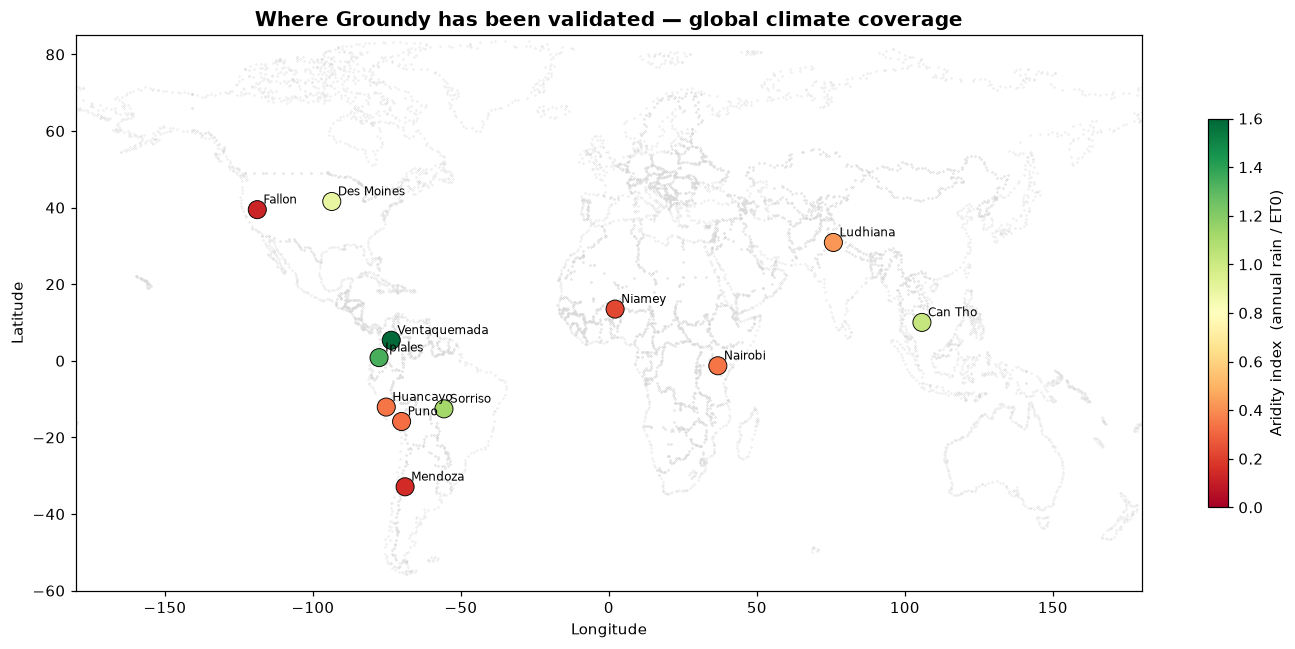

,site,zone,tmean,rain,aridity
8,Fallon,"Desierto con riego, EE.UU.",13.7,174,0.12
7,Mendoza,"Árido con riego (vid), Argentina",18.1,283,0.15
10,Huancayo,"Valle del Mantaro, Junín",12.2,398,0.34
11,Puno,"Altiplano, Puno",9.9,441,0.32
5,Niamey,"Sahel, Níger",29.0,555,0.22
1,Nairobi,"Altiplano tropical, Kenia",20.0,581,0.34
4,Ludhiana,"Semiárido con riego, India",25.1,733,0.42
3,Des Moines,"Templado húmedo (maíz), EE.UU.",10.5,857,0.89
0,Ipiales,"Altiplano andino, Colombia",11.0,1105,1.34
2,Sorriso,"Cerrado (soya), Brasil",25.9,1502,1.12


In [10]:
sdf = pd.DataFrame([{'site':k,'lat':v['lat'],'lon':v['lon'],'tmean':v['tmean'],
                    'rain':v['rain_yr'],'aridity':v['aridity'],'zone':v['zone']}
                   for k,v in sites.items()])
w = demo['world']
fig, ax = plt.subplots(figsize=(13,6))
ax.scatter(w['lon'], w['lat'], s=0.08, color='#d9d9d9')          # world coastlines
sc = ax.scatter(sdf.lon, sdf.lat, c=sdf.aridity, cmap='RdYlGn', s=140,
                edgecolor='black', linewidth=.6, zorder=3, vmin=0, vmax=1.6)
for _, r in sdf.iterrows():
    ax.annotate(r['site'], (r.lon, r.lat), xytext=(4,4), textcoords='offset points', fontsize=8)
plt.colorbar(sc, label='Aridity index  (annual rain / ET0)', shrink=.7)
ax.set_title('Where Groundy has been validated — global climate coverage', fontsize=13, weight='bold')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_xlim(-180,180); ax.set_ylim(-60,85)
plt.tight_layout(); plt.show()
sdf[['site','zone','tmean','rain','aridity']].sort_values('rain')


## 2. Climate diversity (NASA POWER)

Each site occupies a different region of **climate space** — Groundy must handle them all.


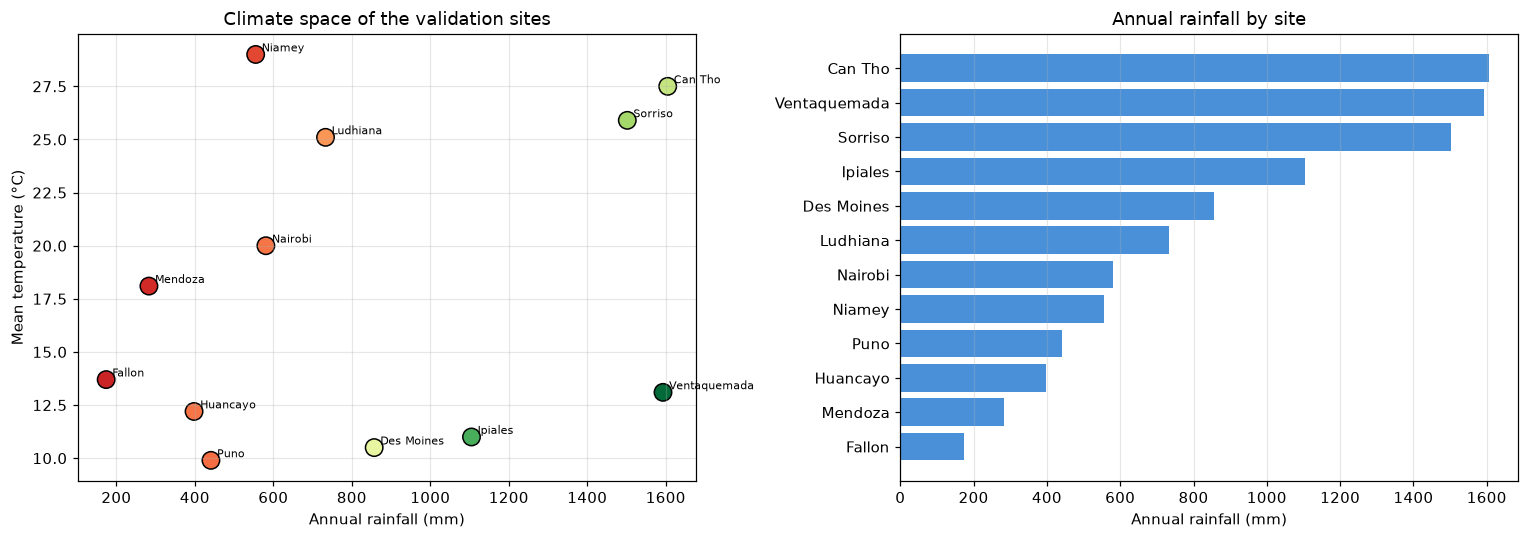

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
# (a) climate space
sc = ax[0].scatter(sdf.rain, sdf.tmean, c=sdf.aridity, cmap='RdYlGn', s=130, edgecolor='k', vmin=0, vmax=1.6)
for _, r in sdf.iterrows(): ax[0].annotate(r['site'], (r.rain, r.tmean), fontsize=7, xytext=(4,2), textcoords='offset points')
ax[0].set_xlabel('Annual rainfall (mm)'); ax[0].set_ylabel('Mean temperature (°C)')
ax[0].set_title('Climate space of the validation sites'); ax[0].grid(alpha=.3)
# (b) annual rainfall ranking
s2 = sdf.sort_values('rain')
ax[1].barh(s2.site, s2.rain, color='#4a90d9'); ax[1].set_xlabel('Annual rainfall (mm)')
ax[1].set_title('Annual rainfall by site'); ax[1].grid(axis='x', alpha=.3)
plt.tight_layout(); plt.show()


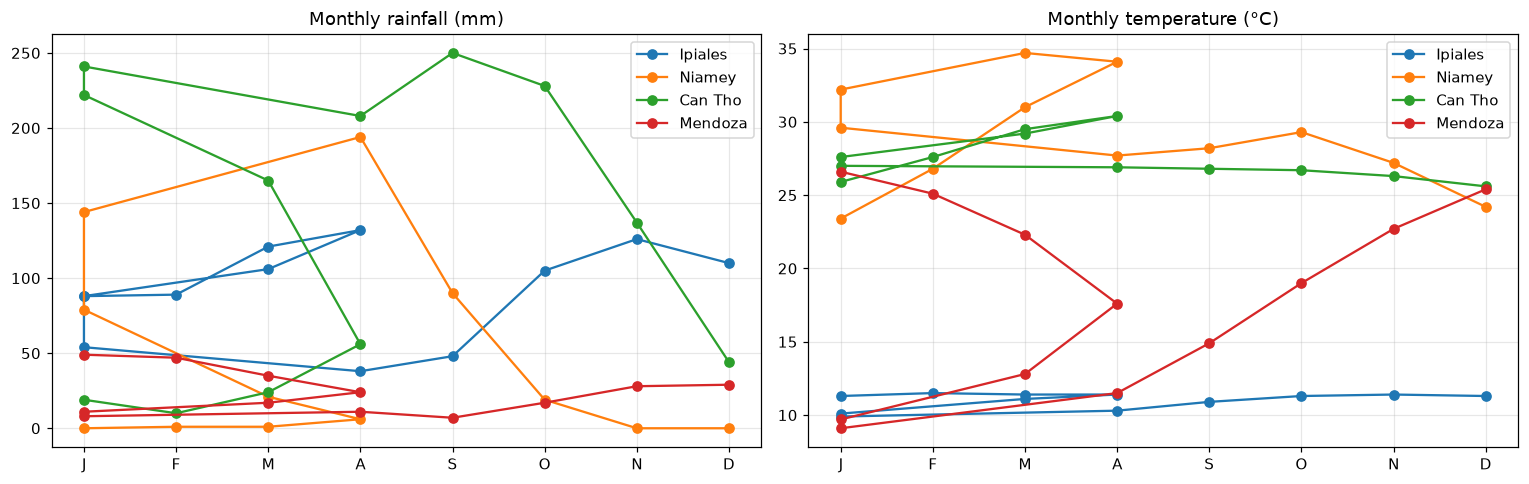

In [12]:
# Seasonal cycle (monthly rain) for four contrasting climates
months = ['J','F','M','A','M','J','J','A','S','O','N','D']
pick = ['Ipiales','Niamey','Can Tho','Mendoza']
fig, ax = plt.subplots(1, 2, figsize=(14,4.5))
for s in pick:
    ax[0].plot(months, sites[s]['monthly']['r'], marker='o', label=s)
    ax[1].plot(months, sites[s]['monthly']['t'], marker='o', label=s)
ax[0].set_title('Monthly rainfall (mm)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_title('Monthly temperature (°C)'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


## 3. Data quality — two independent rainfall sources agree

Groundy cross-checks **NASA POWER** (reanalysis) against **GPM IMERG** (satellite).
Agreement builds trust; the gap becomes an honest uncertainty range shown to the user.


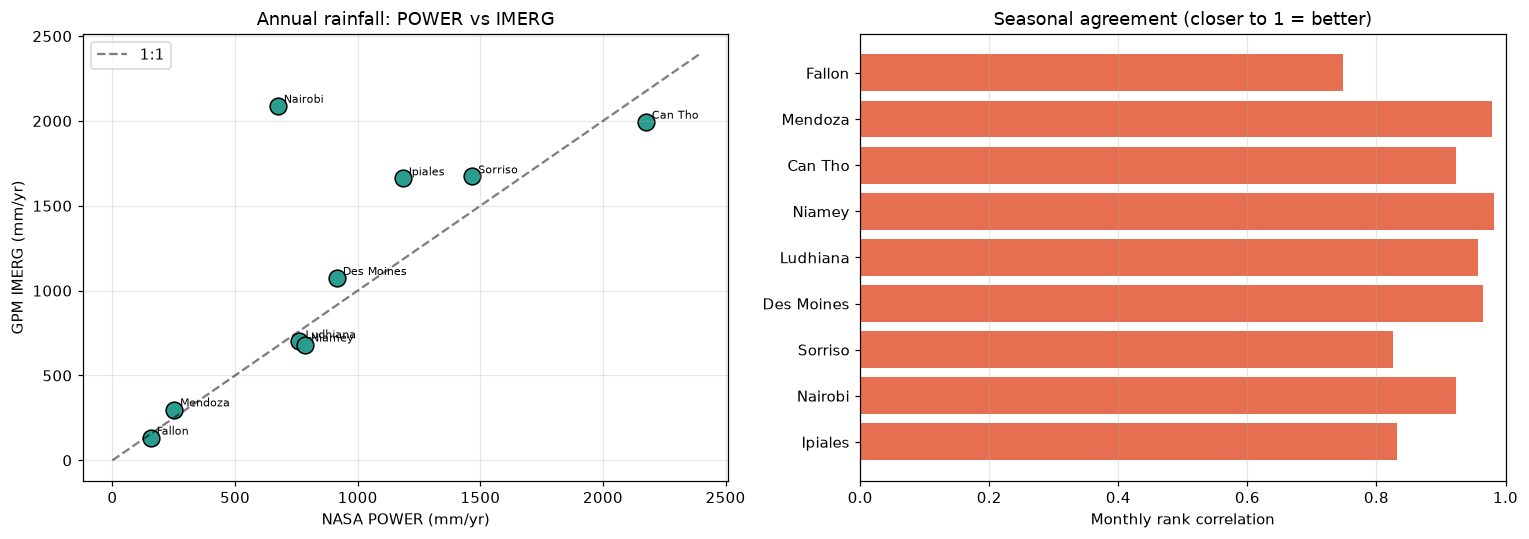

In [13]:
rr = pd.DataFrame(demo['meta']['rain_sources']).T
fig, ax = plt.subplots(1, 2, figsize=(14,5))
mx = max(rr.power.max(), rr.imerg.max())*1.1
ax[0].plot([0,mx],[0,mx],'k--',alpha=.5, label='1:1')
ax[0].scatter(rr.power, rr.imerg, s=120, c='#2a9d8f', edgecolor='k')
for i,r in rr.iterrows(): ax[0].annotate(i,(r.power,r.imerg),fontsize=7,xytext=(4,2),textcoords='offset points')
ax[0].set_xlabel('NASA POWER (mm/yr)'); ax[0].set_ylabel('GPM IMERG (mm/yr)')
ax[0].set_title('Annual rainfall: POWER vs IMERG'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].barh(rr.index, rr['corr'], color='#e76f51'); ax[1].set_xlim(0,1)
ax[1].set_xlabel('Monthly rank correlation'); ax[1].set_title('Seasonal agreement (closer to 1 = better)'); ax[1].grid(axis='x',alpha=.3)
plt.tight_layout(); plt.show()


## 4. Vegetation & soil dynamics from satellites (MODIS · SMAP)

Monthly **NDVI** (greenness) and **soil moisture** reveal each region's growing season.


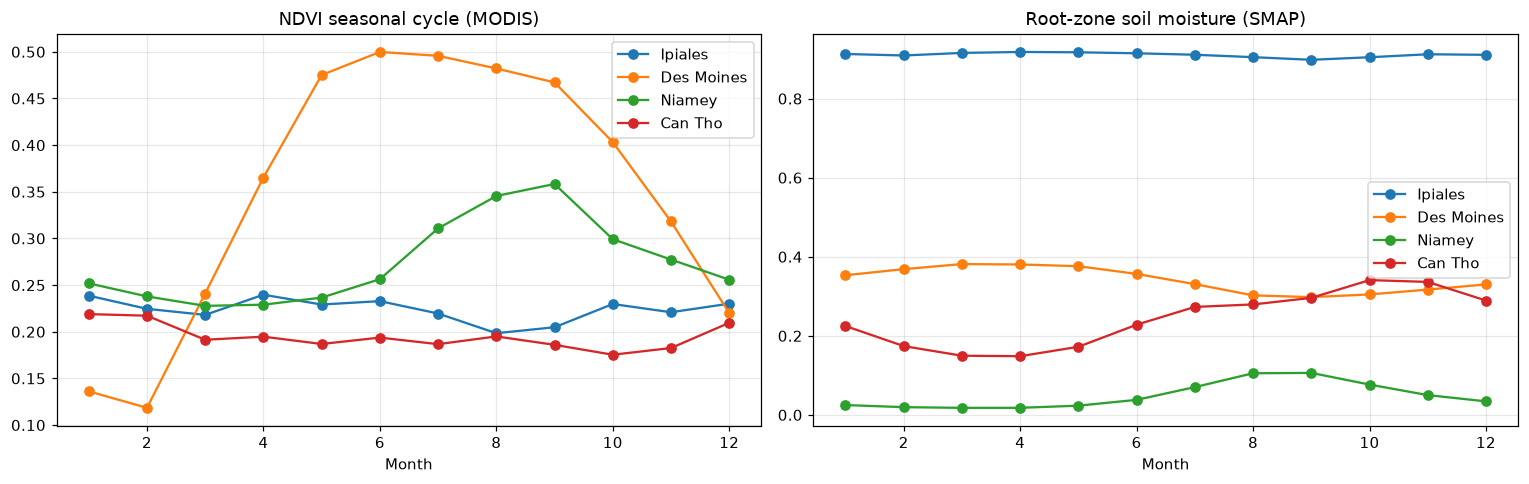

In [14]:
gee['mo'] = gee.month.str[-2:].astype(int)
pick = ['Ipiales','Des Moines','Niamey','Can Tho']
fig, ax = plt.subplots(1, 2, figsize=(14,4.5))
for s in pick:
    g = gee[gee.site==s].groupby('mo')
    ax[0].plot(range(1,13), g.ndvi.mean().reindex(range(1,13)), marker='o', label=s)
    ax[1].plot(range(1,13), g.sm_root.mean().reindex(range(1,13)), marker='o', label=s)
ax[0].set_title('NDVI seasonal cycle (MODIS)'); ax[0].set_xlabel('Month'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_title('Root-zone soil moisture (SMAP)'); ax[1].set_xlabel('Month'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


## 5. The crop knowledge base (FAO EcoCrop — 42 crops)

Every crop has an optimal climate window. Groundy matches a site's real climate against
all 42 to rank suitability and build rotations.


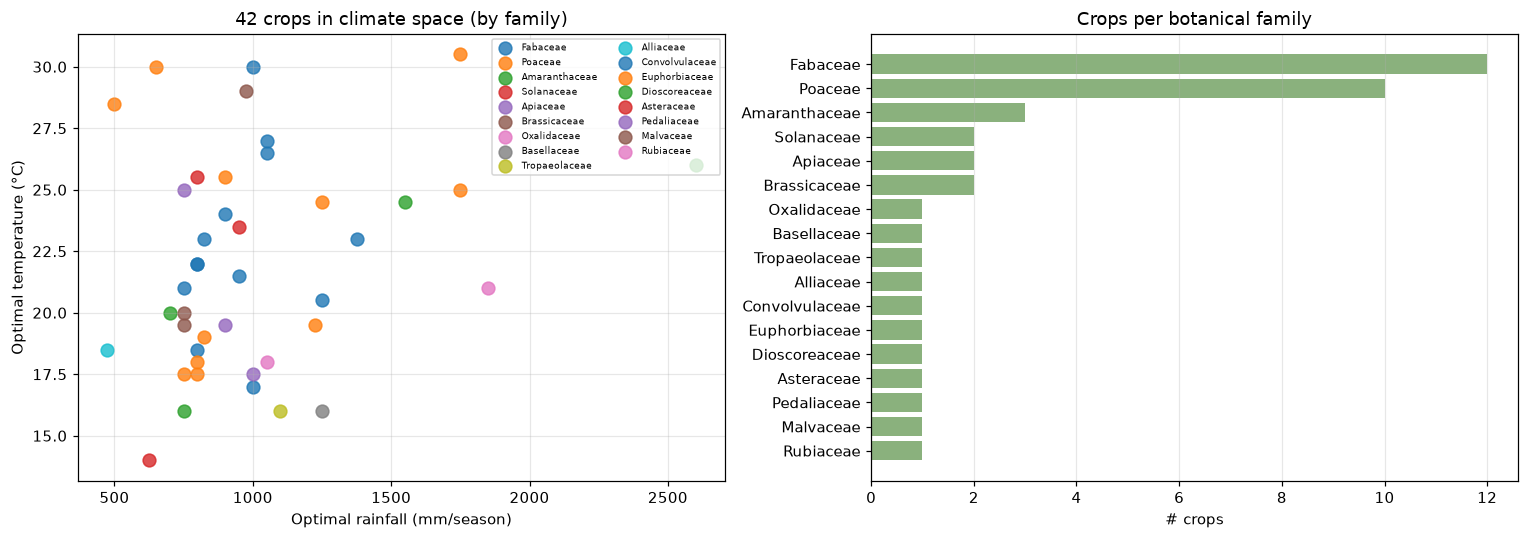

Legumes (nitrogen fixers): 12 of 42 crops


In [15]:
c = crops_req.copy()
c['t_mid'] = (c.t_opt_min + c.t_opt_max)/2
c['r_mid'] = (c.rain_opt_min + c.rain_opt_max)/2
fig, ax = plt.subplots(1, 2, figsize=(14,5))
fams = c.family.value_counts()
for fam in fams.index:
    sub = c[c.family==fam]
    ax[0].scatter(sub.r_mid, sub.t_mid, s=70, label=fam, alpha=.8)
ax[0].set_xlabel('Optimal rainfall (mm/season)'); ax[0].set_ylabel('Optimal temperature (°C)')
ax[0].set_title('42 crops in climate space (by family)'); ax[0].grid(alpha=.3)
ax[0].legend(fontsize=6, ncol=2, loc='upper right')
ax[1].barh(fams.index[::-1], fams.values[::-1], color='#8ab17d')
ax[1].set_title('Crops per botanical family'); ax[1].set_xlabel('# crops'); ax[1].grid(axis='x',alpha=.3)
plt.tight_layout(); plt.show()
print('Legumes (nitrogen fixers):', int(c.is_legume.sum()), 'of', len(c), 'crops')


## 6. Live interactive map — Earth Engine layers 🛰️

Toggle the layers (top-right) and **draw a polygon** over any field using the polygon
tool on the left of the map. Then run section 7.

Layers: NDVI (MODIS 250 m & Sentinel-2 10 m), soil moisture (SMAP), slope (SRTM).


In [16]:
import ee, geemap
SA_EMAIL = 'papanauta-server@kinetic-anvil-457906-e8.iam.gserviceaccount.com'
try:
    cred = ee.ServiceAccountCredentials(SA_EMAIL, str(Path('../secrets/gee_key.json')))
    ee.Initialize(cred, project='kinetic-anvil-457906-e8')
except Exception as e:
    print('Service key not available (', type(e).__name__, ') — using personal login...')
    ee.Authenticate(); ee.Initialize(project='kinetic-anvil-457906-e8')
print('Earth Engine:', ee.String('connected').getInfo())


Earth Engine: connected


In [17]:
ndvi_modis = (ee.ImageCollection('MODIS/061/MOD13Q1').select('NDVI')
              .filterDate('2022-01-01','2025-12-31').mean().multiply(0.0001))
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterDate('2024-01-01','2025-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',30))
      .map(lambda i: i.normalizedDifference(['B8','B4']).rename('NDVI')).median())
sm = (ee.ImageCollection('NASA/SMAP/SPL4SMGP/008').select('sm_rootzone')
      .filterDate('2024-01-01','2025-12-31').mean())
slope = ee.Terrain.slope(ee.Image('USGS/SRTMGL1_003'))
green = {'min':0,'max':0.8,'palette':['#d7191c','#fdae61','#ffffbf','#a6d96a','#1a9641']}
blue  = {'min':0,'max':0.5,'palette':['#8c510a','#d8b365','#f6e8c3','#5ab4ac','#01665e']}
brown = {'min':0,'max':30, 'palette':['#ffffcc','#fd8d3c','#800026']}
Map = geemap.Map(center=[1.21,-77.28], zoom=11)
Map.addLayer(ndvi_modis, green, 'NDVI MODIS 250m')
Map.addLayer(s2, green, 'NDVI Sentinel-2 10m')
Map.addLayer(sm, blue, 'Soil moisture SMAP')
Map.addLayer(slope, brown, 'Slope (deg)')
Map


Map(center=[1.21, -77.28], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

## 7. Analyze a field — live Groundy API

Uses the polygon you drew in section 6. If you did not draw one, it falls back to a
demo field near Pasto, so the cell always returns a result.

⏳ The first analysis of a new area takes ~60 s (satellite query); repeats are instant (cache).


In [18]:
def drawn_polygon(m):
    """Robustly read the last drawn polygon across geemap versions; None if nothing drawn."""
    for attr in ('user_roi',):
        g = getattr(m, attr, None)
        if g is not None:
            try: return [[float(x),float(y)] for x,y in g.coordinates().getInfo()[0]]
            except Exception: pass
    feats = getattr(m, 'draw_features', None) or []
    if feats:
        try: return [[float(x),float(y)] for x,y in feats[-1].geometry().coordinates().getInfo()[0]]
        except Exception: pass
    return None

coords = drawn_polygon(Map)
if coords is None:
    print('No polygon drawn — using a default demo field near Pasto.')
    coords = [[-77.30,1.15],[-77.28,1.15],[-77.28,1.17],[-77.30,1.17]]
print('Polygon vertices:', len(coords), '· querying Groundy (first run ~60s)...')
area = requests.post(API+'/analizar/area', json={'coords':coords}, timeout=200).json()

print('\n=== FIELD REPORT ===')
print('Area (ha):          ', area['area_ha'])
print('Elevation (m):      ', area['terreno_dentro_de_la_finca']['elevacion_m'])
print('Slope (deg):        ', area['terreno_dentro_de_la_finca']['pendiente_grados'])
print('NDVI Sentinel-2 10m:', area['vegetacion']['ndvi_sentinel2_10m'])
print('Regional climate:   ', area['clima_regional'])
print('Confidence:         ', area['confianza'])
print('Best rotation:      ', area.get('mejor_rotacion'))
pd.DataFrame(area['rotaciones'])[['name','score']].rename(columns={'name':'Rotation','score':'Score'})


No polygon drawn — using a default demo field near Pasto.
Polygon vertices: 4 · querying Groundy (first run ~60s)...

=== FIELD REPORT ===
Area (ha):           494.47
Elevation (m):       {'media': 2850.244, 'desv': 97.613, 'min': 2686.0, 'max': 3101.0}
Slope (deg):         {'media': 12.115, 'desv': 9.362, 'min': 0.0, 'max': 46.839}
NDVI Sentinel-2 10m: {'media': 0.55, 'desv': 0.218, 'min': -0.07, 'max': 0.888}
Regional climate:    {'tmean_c': 13.2, 'rain_mm_yr': 1105, 'et0_mm_yr': 922, 'aridity': 1.2, 'rain_imerg_mm_yr': 2225, 'rain_range_mm': [1105, 2225]}
Confidence:          desconocida
Best rotation:       Papa - Cebolla - Lenteja


,Rotation,Score
0,Papa - Cebolla - Lenteja,87.2
1,Papa - Quinua - Lenteja,85.9
2,Papa - Colza (canola) - Lenteja,85.8
3,Papa - Cebada - Lenteja,85.8
4,Papa - Avena - Lenteja,84.4


## 8. Monthly profile & crop suitability for the field

Satellite time series and the best-fit crops for the centroid of your field.


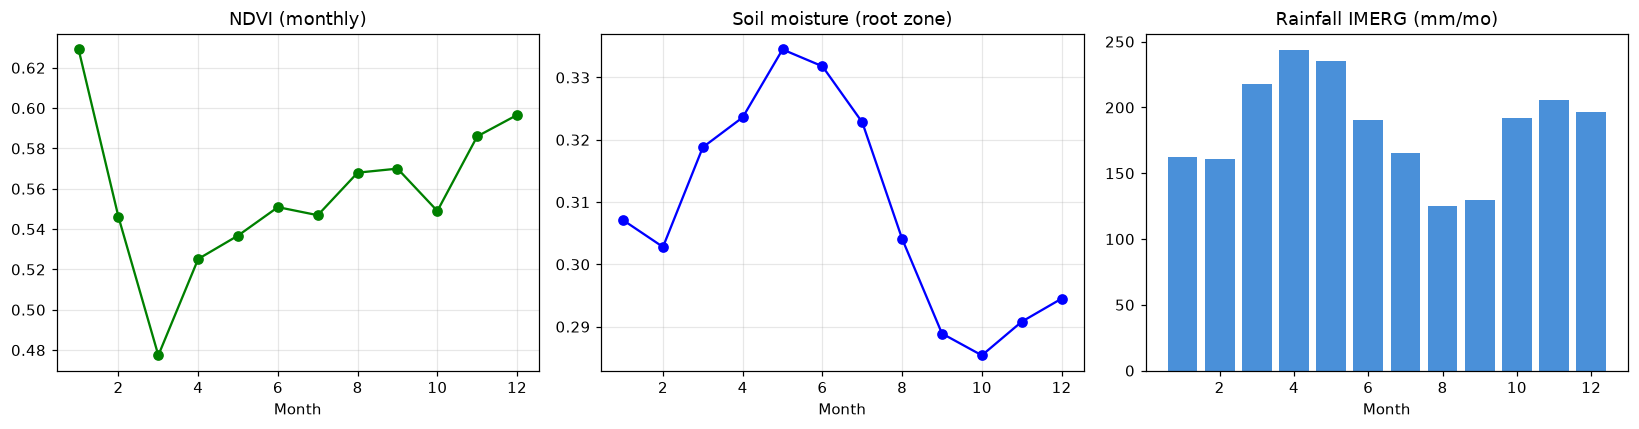

Top crops for this field:


,id,suit,best_month,limits
0,papa,0.92,oct,ninguno
1,cebolla,0.83,mar,ninguno
2,quinua,0.76,oct,lluvia
3,colza,0.73,nov,temperatura
4,cebada,0.73,oct,lluvia
5,centeno,0.65,nov,lluvia


In [21]:
cen = area['centroide']
rp = requests.post(API+'/analizar/punto', json={'lat':cen['lat'],'lon':cen['lon']}, timeout=200).json()
vm = rp['vegetation_monthly']; mo = range(1,13)
fig, ax = plt.subplots(1, 3, figsize=(15,4))
ax[0].plot(mo, vm['ndvi'], 'g-o'); ax[0].set_title('NDVI (monthly)'); ax[0].grid(alpha=.3)
ax[1].plot(mo, vm['sm_root'], 'b-o'); ax[1].set_title('Soil moisture (root zone)'); ax[1].grid(alpha=.3)
ax[2].bar(mo, vm['rain_imerg'], color='#4a90d9'); ax[2].set_title('Rainfall IMERG (mm/mo)')
for a in ax: a.set_xlabel('Month')
plt.tight_layout(); plt.show()
print('Top crops for this field:')
pd.DataFrame(rp['crops_top'])[['id','suit','best_month','limits']]
